In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("fakenews.csv")

In [2]:
# Handle missing text
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Display dataset information
print("Dataset loaded successfully!")
print("Total articles:", len(df))

print("\nNews categories:")
print(df["label"].value_counts())

print("\nSample data:")
print(df[["label", "text"]].head())

Dataset loaded successfully!
Total articles: 2212

News categories:
label
Fake    1110
Real    1102
Name: count, dtype: int64

Sample data:
  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...


In [3]:
# Define emotion-related words
emotion_dictionary = {
    "positive_emotion": [
        "happy", "success", "good", "excellent", "hope",
        "benefit", "support", "love", "win", "positive"
    ],

    "negative_emotion": [
        "bad", "wrong", "failure", "danger", "fear",
        "crisis", "negative", "problem", "harm", "threat"
    ],

    "anger": [
        "angry", "anger", "hate", "attack", "rage",
        "furious", "blame", "violent", "outrage", "hostile"
    ],

    "anxiety": [
        "afraid", "anxiety", "worry", "worried", "uncertain",
        "nervous", "panic", "concern", "threat", "risk"
    ],

    "sadness": [
        "sad", "grief", "loss", "cry", "sorrow",
        "tragic", "unhappy", "pain", "lonely", "suffering"
    ]
}

print("Emotional categories created:")
for category in emotion_dictionary:
    print(category, ":", len(emotion_dictionary[category]), "words")


Emotional categories created:
positive_emotion : 10 words
negative_emotion : 10 words
anger : 10 words
anxiety : 10 words
sadness : 10 words


In [4]:
import re

# Function to count emotional words
def count_emotions(text):
    words = re.findall(r"\b[a-z]+\b", text.lower())

    emotion_counts = {}

    for category, emotion_words in emotion_dictionary.items():
        emotion_counts[category] = sum(
            1 for word in words if word in emotion_words
        )

    return emotion_counts


# Apply emotion analysis to each article
emotion_results = df["text"].apply(count_emotions)

# Convert results into a DataFrame
emotion_df = pd.DataFrame(emotion_results.tolist())

# Add news category
emotion_df["label"] = df["label"].values

# Display results
print(emotion_df.head())

print("\nTotal emotional words by category:")
print(emotion_df.drop(columns=["label"]).sum())

   positive_emotion  negative_emotion  anger  anxiety  sadness label
0                 0                 0      0        0        0  Real
1                 0                 0      0        1        0  Real
2                 0                 0      0        0        0  Fake
3                 0                 0      0        0        0  Fake
4                 0                 1      0        0        0  Real

Total emotional words by category:
positive_emotion      0
negative_emotion    443
anger                 0
anxiety             231
sadness               0
dtype: int64


In [5]:
# Compare average emotional word counts by news category
emotion_comparison = (
    emotion_df.groupby("label")[
        list(emotion_dictionary.keys())
    ]
    .mean()
    .round(2)
)

# Display results
print("Average Emotional Word Counts in Real vs Fake News:\n")
print(emotion_comparison)

Average Emotional Word Counts in Real vs Fake News:

       positive_emotion  negative_emotion  anger  anxiety  sadness
label                                                             
Fake                0.0               0.2    0.0     0.10      0.0
Real                0.0               0.2    0.0     0.11      0.0


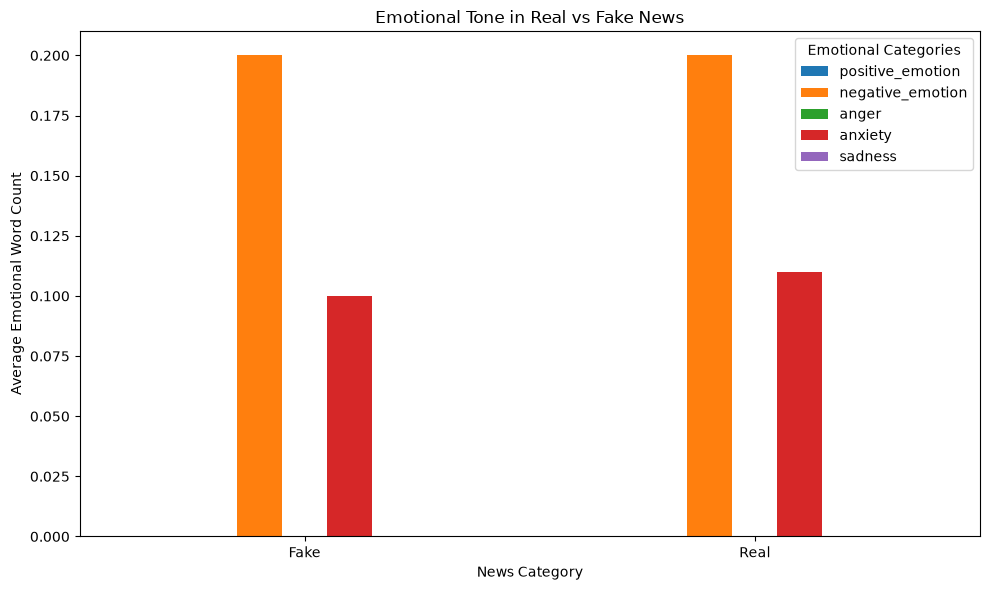

In [6]:
# Plot emotional tone comparison
emotion_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Emotional Tone in Real vs Fake News")
plt.xlabel("News Category")
plt.ylabel("Average Emotional Word Count")
plt.xticks(rotation=0)
plt.legend(title="Emotional Categories")
plt.tight_layout()
plt.show()

In [7]:
# Save article-level emotional analysis
emotion_df.to_csv("T22_emotional_analysis.csv", index=False)

# Save Real vs Fake comparison
emotion_comparison.to_csv("T22_emotional_comparison.csv")

# Display comparison
print("Emotional Tone Comparison:\n")
print(emotion_comparison)

# Find the category with the highest average negative emotion
if "negative_emotion" in emotion_comparison.columns:
    highest_negative = emotion_comparison["negative_emotion"].idxmax()
    print(
        f"\n{highest_negative} news has the higher "
        "average negative-emotion word count."
    )

print("\nEmotional tone analysis completed successfully!")

Emotional Tone Comparison:

       positive_emotion  negative_emotion  anger  anxiety  sadness
label                                                             
Fake                0.0               0.2    0.0     0.10      0.0
Real                0.0               0.2    0.0     0.11      0.0

Fake news has the higher average negative-emotion word count.

Emotional tone analysis completed successfully!
